#  Fitness Level Prediction — Machine Learning Project
### Final Project — Team 5

This notebook builds and evaluates **5 Machine Learning models** to predict fitness level from health & activity data:

1. **KNN** (K-Nearest Neighbors)
2. **Linear Regression**
3. **Logistic Regression** (Classification)
4. **XGBoost**
5. **SVM** (Support Vector Machine — Classification)

> **Target Variable**: `fitness_level` (continuous: 0 – 20.63)
> - For **Regression** models (KNN, Linear Regression, XGBoost): predict the raw continuous value
> - For **Classification** models (Logistic Regression, SVM): predict binned fitness categories (Low / Medium / High)


In [113]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor


from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC


from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)


import joblib
import os

print("All libraries imported successfully ✅")


All libraries imported successfully ✅


In [114]:
df = pd.read_csv('my_dataset.csv')
print(f"Dataset Shape: {df.shape}")
print(f"Total Rows: {df.shape[0]:,}  |  Total Columns: {df.shape[1]}")
df.head(10)


Dataset Shape: (687701, 22)
Total Rows: 687,701  |  Total Columns: 22


,ID,age,gender,height_cm,weight_kg,bmi,activity_type,duration_minutes,intensity,calories_burned,...,resting_heart_rate,blood_pressure_systolic,blood_pressure_diastolic,endurance_level,sleep_hours,stress_level,hydration_level,smoking_status,health_condition,fitness_level
0,1,56,F,165.3,50.55,18.50,Dancing,42.1,Low,3.3,...,69.5,110.7,72.9,5.37,6.6,4,1.5,Never,NaN,0.04
1,2,56,F,165.3,55.38,20.27,Swimming,66.9,Low,2.9,...,69.5,110.7,72.9,5.39,8.1,3,1.8,Never,NaN,0.07
2,3,56,F,165.3,56.49,20.68,Swimming,20.0,Medium,2.6,...,69.5,110.7,72.9,5.42,6.2,5,2.7,Never,NaN,0.09
3,4,56,F,165.3,52.23,19.12,Weight Training,23.5,Medium,10.7,...,69.5,110.7,72.9,5.44,7.2,4,2.6,Never,NaN,0.21
4,5,56,F,165.3,53.96,19.75,Swimming,75.0,Medium,12.7,...,69.5,110.7,72.9,5.47,7.1,7,1.5,Never,NaN,0.33
5,6,56,F,165.3,55.56,20.33,HIIT,86.5,Medium,6.8,...,69.5,110.7,72.9,5.49,7.5,8,2.2,Never,NaN,0.37
6,7,56,F,165.3,53.89,19.72,Weight Training,24.4,High,12.4,...,69.5,110.7,72.9,5.52,6.6,7,2.8,Never,NaN,0.51
7,8,56,F,165.3,55.91,20.46,HIIT,20.0,Low,12.9,...,69.5,110.7,72.9,5.55,6.1,4,1.6,Never,NaN,0.58
8,9,56,F,165.3,57.47,21.03,HIIT,20.0,Medium,19.7,...,69.5,110.7,72.9,5.57,7.2,5,3.3,Never,NaN,0.68
9,10,56,F,165.3,54.29,19.87,Weight Training,20.0,Medium,12.8,...,69.5,110.7,72.9,5.60,5.6,9,2.0,Never,NaN,0.82


In [115]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 687701 entries, 0 to 687700
Data columns (total 22 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        687701 non-null  int64  
 1   age                       687701 non-null  int64  
 2   gender                    687701 non-null  str    
 3   height_cm                 687701 non-null  float64
 4   weight_kg                 687701 non-null  float64
 5   bmi                       687701 non-null  float64
 6   activity_type             687701 non-null  str    
 7   duration_minutes          687701 non-null  float64
 8   intensity                 687701 non-null  str    
 9   calories_burned           687701 non-null  float64
 10  daily_steps               687701 non-null  int64  
 11  avg_heart_rate            687701 non-null  int64  
 12  resting_heart_rate        687701 non-null  float64
 13  blood_pressure_systolic   687701 non-null  float64
 14 

In [116]:
df.describe().round(2)


,ID,age,height_cm,weight_kg,bmi,duration_minutes,calories_burned,daily_steps,avg_heart_rate,resting_heart_rate,blood_pressure_systolic,blood_pressure_diastolic,endurance_level,sleep_hours,stress_level,hydration_level,fitness_level
count,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00,687701.00
mean,343851.00,41.66,168.59,61.73,21.66,74.03,15.38,8628.37,131.45,70.01,120.00,80.19,9.49,7.05,5.47,2.50,9.52
std,198522.32,13.58,9.14,8.55,1.94,35.10,9.99,2054.76,17.81,5.07,10.01,8.24,2.25,0.97,1.91,0.58,5.50
min,1.00,18.00,145.00,39.76,18.50,20.00,0.80,-419.00,82.00,51.10,78.00,53.70,4.53,4.00,1.00,1.50,0.02
25%,171926.00,30.00,161.70,55.50,20.06,46.30,7.80,7203.00,118.00,66.50,113.10,74.60,7.82,6.40,4.00,2.00,4.77
50%,343851.00,42.00,168.20,61.06,21.64,72.80,13.00,8607.00,130.00,70.00,120.20,80.10,9.46,7.00,5.00,2.50,9.51
75%,515776.00,53.00,175.30,67.31,23.27,99.50,20.70,10027.00,144.00,73.50,127.00,85.70,11.05,7.70,7.00,3.00,14.23
max,687701.00,64.00,198.50,98.11,24.90,152.10,92.00,17241.00,206.00,87.10,152.70,112.10,18.84,10.00,10.00,3.50,21.93


In [117]:

missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct})
missing_df[missing_df['Missing Count'] > 0]


,Missing Count,Percentage (%)
health_condition,490275,71.29


## 3. Exploratory Data Analysis (EDA)


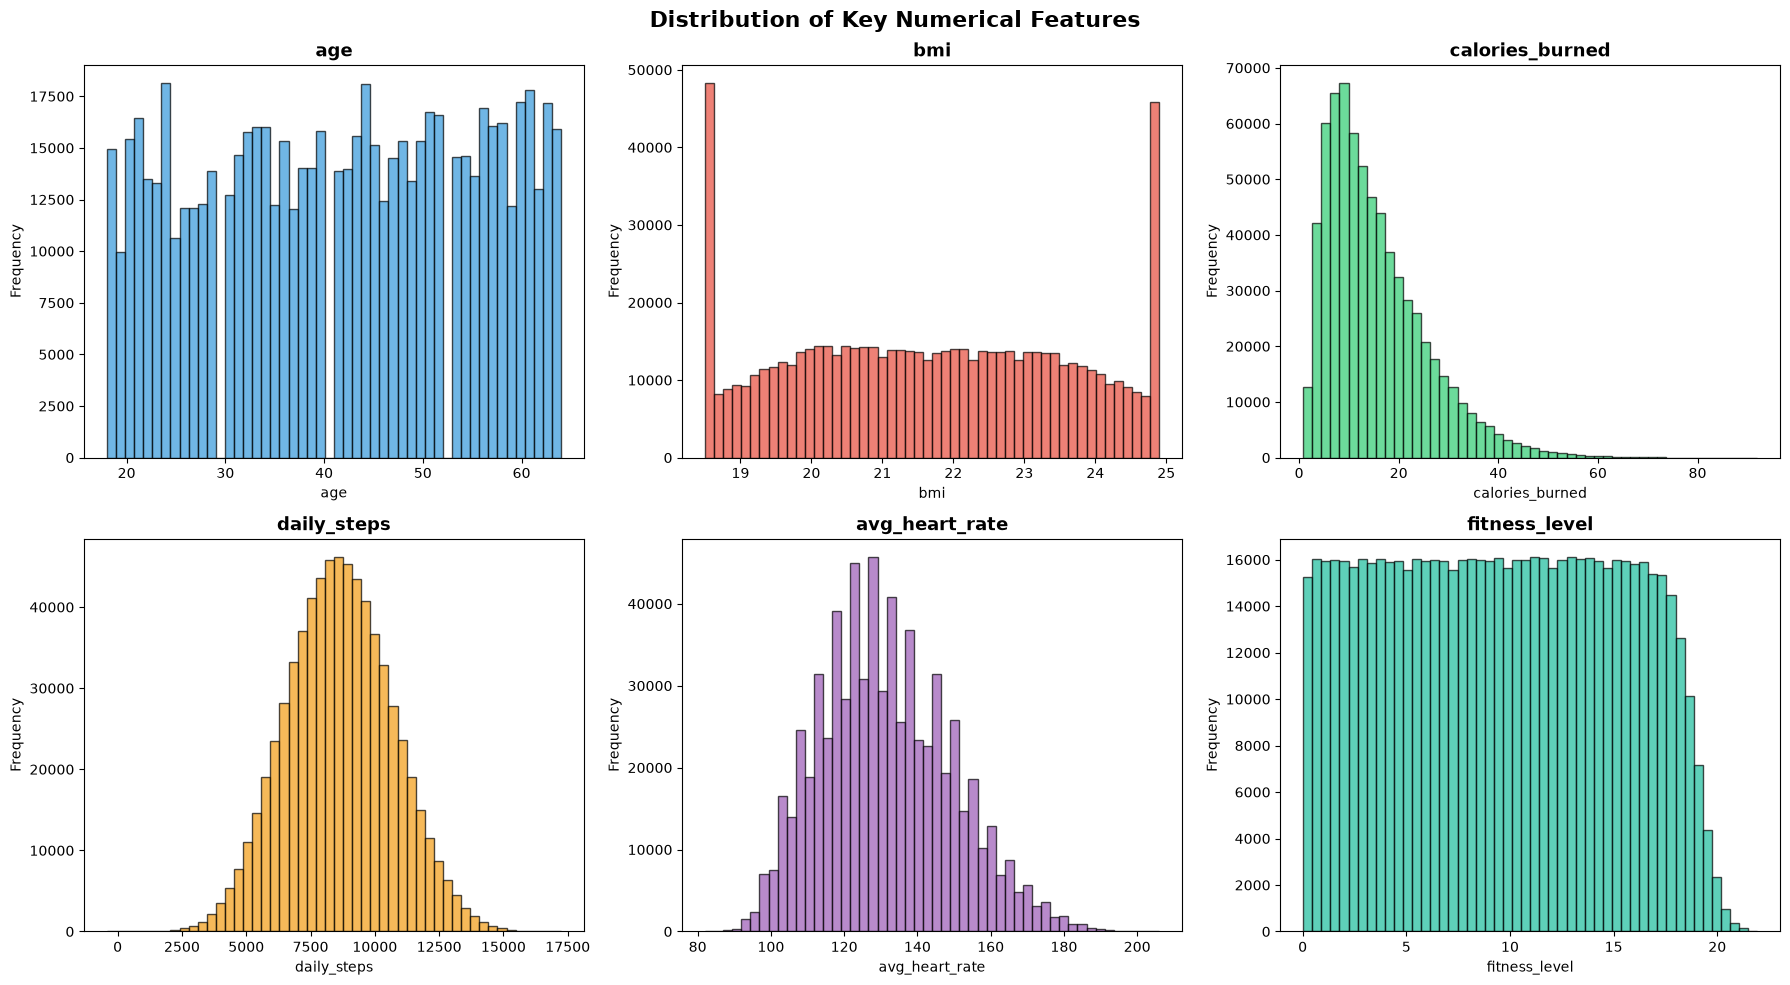

In [118]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Distribution of Key Numerical Features', fontsize=16, fontweight='bold')

num_features = ['age', 'bmi', 'calories_burned', 'daily_steps', 'avg_heart_rate', 'fitness_level']
colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']

for i, (feat, color) in enumerate(zip(num_features, colors)):
    ax = axes[i // 3, i % 3]
    ax.hist(df[feat], bins=50, color=color, edgecolor='black', alpha=0.7)
    ax.set_title(feat, fontsize=13, fontweight='bold')
    ax.set_xlabel(feat)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()


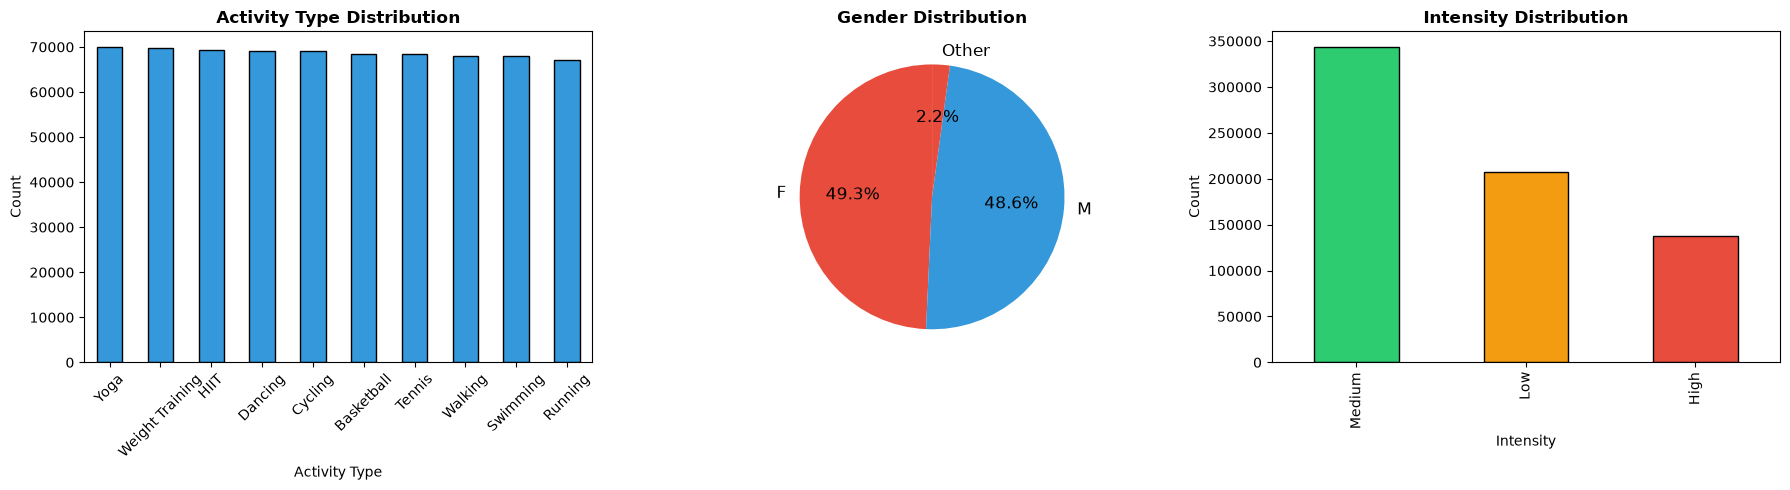

In [119]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df['activity_type'].value_counts().plot.bar(ax=axes[0], color='#3498db', edgecolor='black')
axes[0].set_title('Activity Type Distribution', fontweight='bold')
axes[0].set_xlabel('Activity Type')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Gender
df['gender'].value_counts().plot.pie(ax=axes[1], autopct='%1.1f%%', colors=['#e74c3c', '#3498db'],
                                      startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Gender Distribution', fontweight='bold')
axes[1].set_ylabel('')

# Intensity
df['intensity'].value_counts().plot.bar(ax=axes[2], color=['#2ecc71', '#f39c12', '#e74c3c'], edgecolor='black')
axes[2].set_title('Intensity Distribution', fontweight='bold')
axes[2].set_xlabel('Intensity')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()


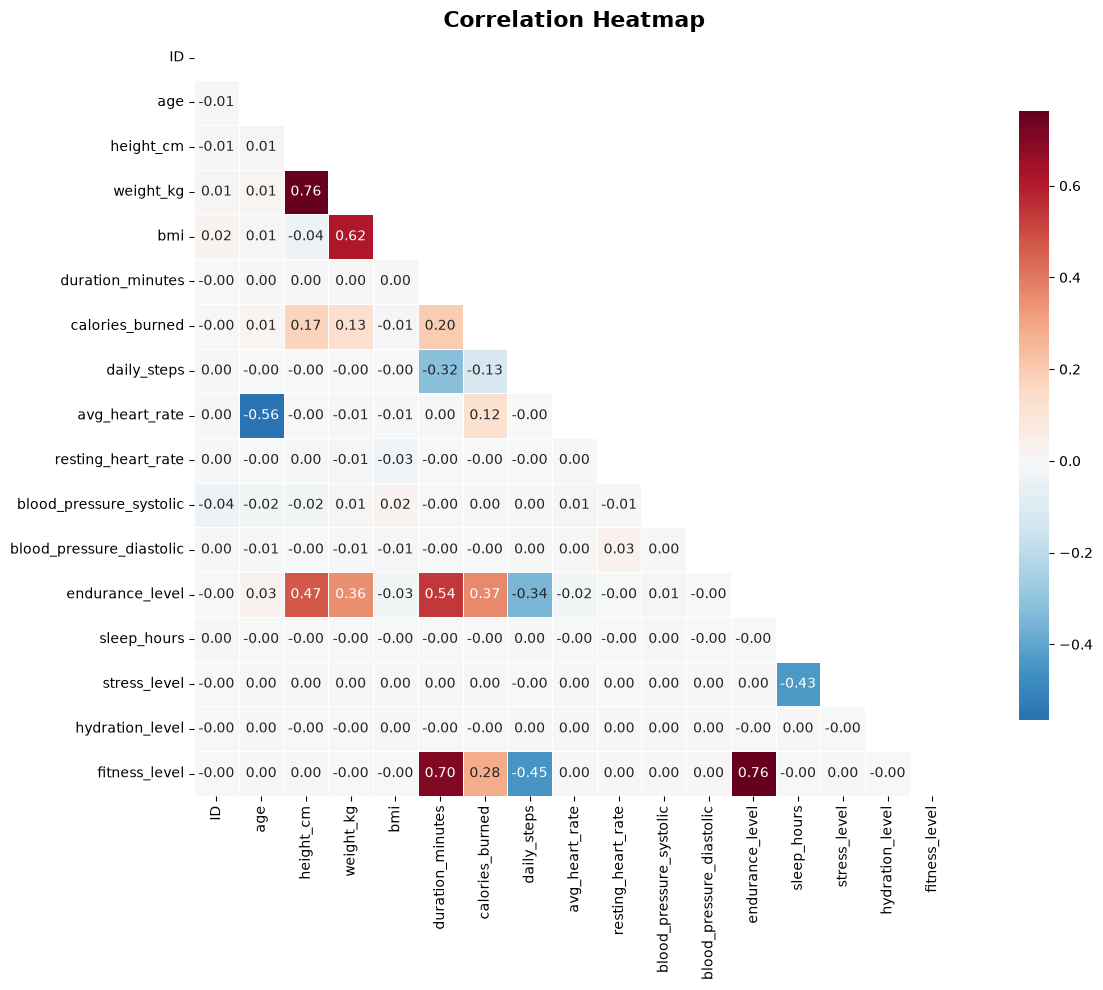

In [120]:
plt.figure(figsize=(14, 10))
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


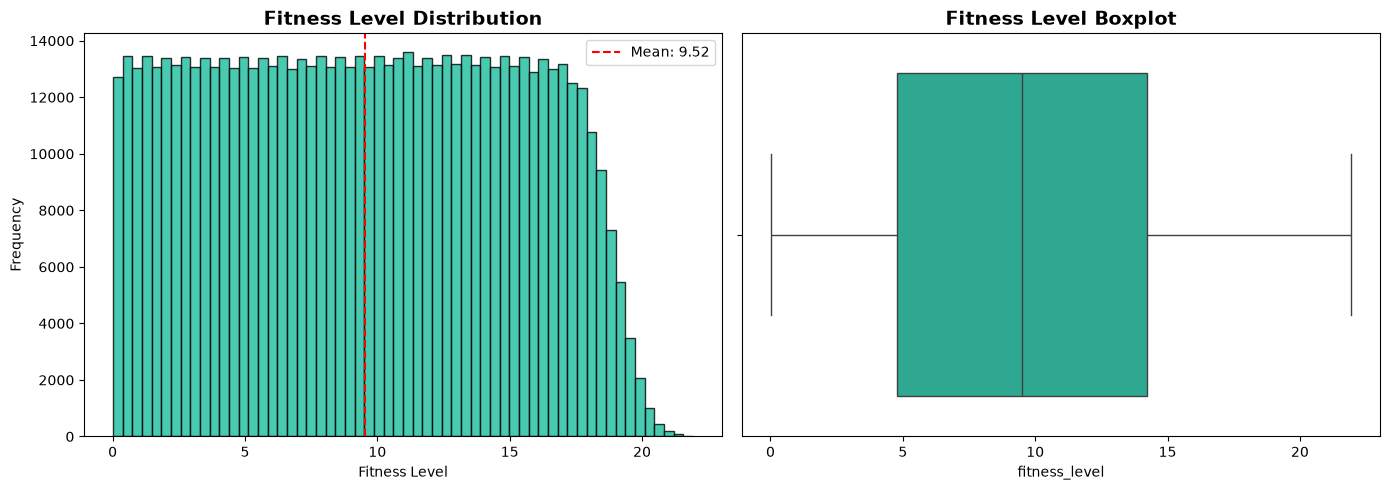

In [121]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['fitness_level'], bins=60, color='#1abc9c', edgecolor='black', alpha=0.8)
axes[0].set_title('Fitness Level Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Fitness Level')
axes[0].set_ylabel('Frequency')
axes[0].axvline(df['fitness_level'].mean(), color='red', linestyle='--', label=f"Mean: {df['fitness_level'].mean():.2f}")
axes[0].legend()

# Boxplot
sns.boxplot(x=df['fitness_level'], ax=axes[1], color='#1abc9c')
axes[1].set_title('Fitness Level Boxplot', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


In [122]:
df.drop(columns=['ID'], inplace=True)

df['health_condition'].fillna('None', inplace=True)

print("Missing values after cleaning:")
print(df.isnull().sum().sum(), "total missing values")
print(f"\nDataset shape: {df.shape}")


Missing values after cleaning:
490275 total missing values

Dataset shape: (687701, 21)


In [123]:
le_gender = LabelEncoder()
df['gender'] = le_gender.fit_transform(df['gender'])

intensity_order = {'Low': 0, 'Medium': 1, 'High': 2}
df['intensity'] = df['intensity'].map(intensity_order)

df = pd.get_dummies(df, columns=['activity_type', 'smoking_status', 'health_condition'], 
                    drop_first=True, dtype=int)

print(f"Shape after encoding: {df.shape}")
print(f"\nColumns: {list(df.columns)}")


Shape after encoding: (687701, 31)

Columns: ['age', 'gender', 'height_cm', 'weight_kg', 'bmi', 'duration_minutes', 'intensity', 'calories_burned', 'daily_steps', 'avg_heart_rate', 'resting_heart_rate', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'endurance_level', 'sleep_hours', 'stress_level', 'hydration_level', 'fitness_level', 'activity_type_Cycling', 'activity_type_Dancing', 'activity_type_HIIT', 'activity_type_Running', 'activity_type_Swimming', 'activity_type_Tennis', 'activity_type_Walking', 'activity_type_Weight Training', 'activity_type_Yoga', 'smoking_status_Former', 'smoking_status_Never', 'health_condition_Diabetes', 'health_condition_Hypertension']


Fitness Category Distribution:
fitness_category
0    248218
1    250042
2    189441
Name: count, dtype: int64

0 = Low (0 - 6.87)
1 = Medium (6.87 - 13.74)
2 = High (13.74 - 20.63)


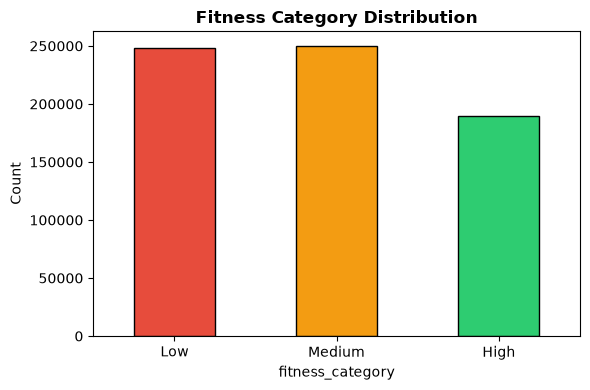

In [124]:
bins = [df['fitness_level'].min() - 0.01, 6.87, 13.74, df['fitness_level'].max() + 0.01]
labels = [0, 1, 2]  # 0=Low, 1=Medium, 2=High
df['fitness_category'] = pd.cut(df['fitness_level'], bins=bins, labels=labels).astype(int)

print("Fitness Category Distribution:")
print(df['fitness_category'].value_counts().sort_index())
print(f"\n0 = Low (0 - 6.87)")
print(f"1 = Medium (6.87 - 13.74)")
print(f"2 = High (13.74 - 20.63)")

fig, ax = plt.subplots(figsize=(6, 4))
df['fitness_category'].value_counts().sort_index().plot.bar(
    color=['#e74c3c', '#f39c12', '#2ecc71'], edgecolor='black', ax=ax)
ax.set_title('Fitness Category Distribution', fontweight='bold')
ax.set_xticklabels(['Low', 'Medium', 'High'], rotation=0)
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()


In [125]:
SAMPLE_SIZE = 100_000  
np.random.seed(42)

df_sampled = df.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)

df_sampled = df_sampled[df_sampled['daily_steps'] >= 0]
df_sampled = df_sampled[df_sampled['calories_burned'] > 0.5]


df_sampled['calories_per_minute'] = df_sampled['calories_burned'] / df_sampled['duration_minutes']
df_sampled['heart_rate_reserve'] = df_sampled['avg_heart_rate'] - df_sampled['resting_heart_rate']
df_sampled['sleep_quality'] = df_sampled['sleep_hours'] / (df_sampled['stress_level'] + 1)


df_sampled['activity_intensity_score'] = (
    df_sampled['daily_steps'] / 10000 *
    df_sampled['duration_minutes'] / 60 *
    (df_sampled['intensity'] + 1)
)
df_sampled['cardiac_efficiency'] = df_sampled['avg_heart_rate'] / df_sampled['resting_heart_rate']
df_sampled['heart_rate_reserve_pct'] = (
    df_sampled['avg_heart_rate'] - df_sampled['resting_heart_rate']
) / df_sampled['resting_heart_rate']
df_sampled['recovery_score'] = df_sampled['sleep_hours'] * (11 - df_sampled['stress_level'])
df_sampled['energy_per_kg'] = df_sampled['calories_burned'] / df_sampled['weight_kg']
df_sampled['steps_per_kg'] = df_sampled['daily_steps'] / df_sampled['weight_kg']
df_sampled['endurance_age_ratio'] = df_sampled['endurance_level'] / df_sampled['age']
df_sampled['bp_ratio'] = df_sampled['blood_pressure_systolic'] / df_sampled['blood_pressure_diastolic']
df_sampled['sleep_stress_interaction'] = df_sampled['sleep_hours'] * df_sampled['stress_level']

# الميزة المركبة الذهبية 🏆
df_sampled['fitness_indicator'] = (
    df_sampled['endurance_level'] * 0.4 +
    df_sampled['activity_intensity_score'] * 0.3 +
    df_sampled['recovery_score'] * 0.3
)

print(f"Sampled dataset shape: {df_sampled.shape}")


X_reg = df_sampled.drop(columns=['fitness_level', 'fitness_category'])
y_reg = df_sampled['fitness_level']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)


X_clf = df_sampled.drop(columns=['fitness_level', 'fitness_category'])
y_clf = df_sampled['fitness_category']

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

print(f"\nRegression Split  → Train: {X_train_reg.shape}, Test: {X_test_reg.shape}")
print(f"Classification Split → Train: {X_train_clf.shape}, Test: {X_test_clf.shape}")


Sampled dataset shape: (100000, 45)

Regression Split  → Train: (80000, 43), Test: (20000, 43)
Classification Split → Train: (80000, 43), Test: (20000, 43)


In [126]:
# Feature Scaling
scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

scaler_clf = StandardScaler()
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)

print("Feature scaling applied")
print(f"Number of features: {X_train_reg_scaled.shape[1]}")


Feature scaling applied
Number of features: 43


In [127]:
regression_results = {}
classification_results = {}


In [128]:
# Find optimal K using cross-validation
k_values = [3, 5, 7, 9, 11, 15]
cv_scores = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k, weights='distance', n_jobs=-1)
    scores = cross_val_score(knn, X_train_reg_scaled, y_train_reg, cv=5, scoring='r2')
    cv_scores.append(scores.mean())
    print(f"K={k:2d}  |  CV R² = {scores.mean():.4f} ± {scores.std():.4f}")

best_k = k_values[np.argmax(cv_scores)]
print(f"\n Best K = {best_k} with R² = {max(cv_scores):.4f}")


K= 3  |  CV R² = 0.5985 ± 0.0039
K= 5  |  CV R² = 0.6448 ± 0.0041
K= 7  |  CV R² = 0.6638 ± 0.0035
K= 9  |  CV R² = 0.6729 ± 0.0029
K=11  |  CV R² = 0.6782 ± 0.0026
K=15  |  CV R² = 0.6817 ± 0.0020

 Best K = 15 with R² = 0.6817


In [129]:
# Train KNN with best K
knn_model = KNeighborsRegressor(n_neighbors=best_k, weights='distance', n_jobs=-1)
knn_model.fit(X_train_reg_scaled, y_train_reg)
y_pred_knn = knn_model.predict(X_test_reg_scaled)

# Evaluate
knn_mae = mean_absolute_error(y_test_reg, y_pred_knn)
knn_rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_knn))
knn_r2 = r2_score(y_test_reg, y_pred_knn)

regression_results['KNN'] = {'MAE': knn_mae, 'RMSE': knn_rmse, 'R²': knn_r2}

print("=" * 50)
print("     KNN Regression Results")
print("=" * 50)
print(f"  MAE  = {knn_mae:.4f}")
print(f"  RMSE = {knn_rmse:.4f}")
print(f"  R²   = {knn_r2:.4f}")
print("=" * 50)


     KNN Regression Results
  MAE  = 2.5127
  RMSE = 3.1061
  R²   = 0.6824


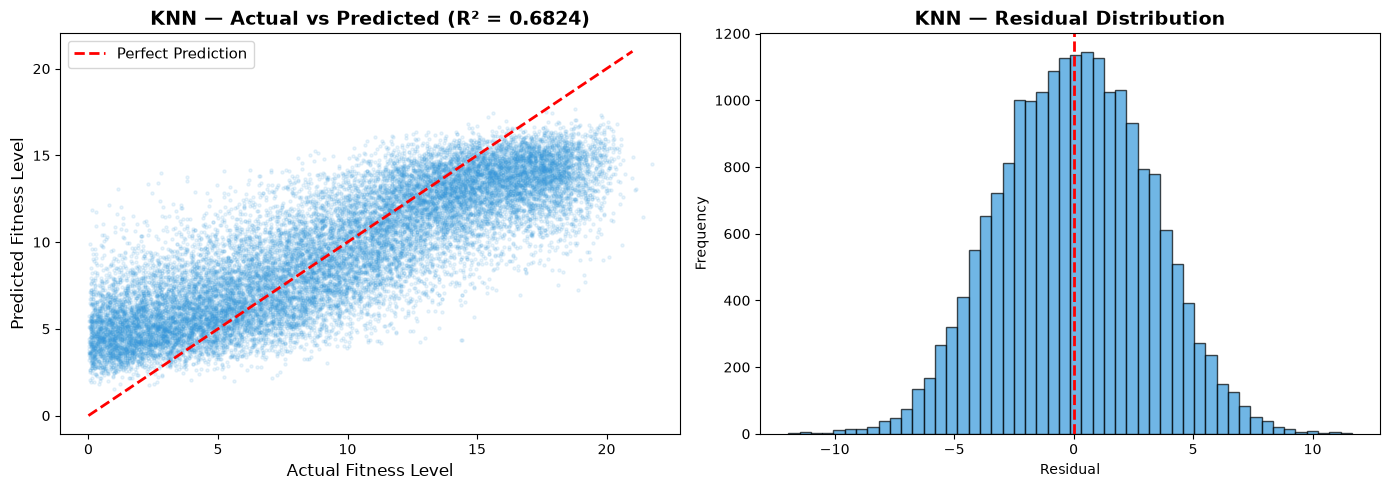

In [130]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot
axes[0].scatter(y_test_reg, y_pred_knn, alpha=0.1, s=5, color='#3498db')
axes[0].plot([0, 21], [0, 21], 'r--', linewidth=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Fitness Level', fontsize=12)
axes[0].set_ylabel('Predicted Fitness Level', fontsize=12)
axes[0].set_title(f'KNN — Actual vs Predicted (R² = {knn_r2:.4f})', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)

# Residuals
residuals = y_test_reg - y_pred_knn
axes[1].hist(residuals, bins=50, color='#3498db', edgecolor='black', alpha=0.7)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('KNN — Residual Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


In [131]:
lr_model = LinearRegression()
lr_model.fit(X_train_reg_scaled, y_train_reg)
y_pred_lr = lr_model.predict(X_test_reg_scaled)


lr_mae = mean_absolute_error(y_test_reg, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_lr))
lr_r2 = r2_score(y_test_reg, y_pred_lr)

regression_results['Linear Regression'] = {'MAE': lr_mae, 'RMSE': lr_rmse, 'R²': lr_r2}

print("=" * 50)
print("     Linear Regression Results")
print("=" * 50)
print(f"  MAE  = {lr_mae:.4f}")
print(f"  RMSE = {lr_rmse:.4f}")
print(f"  R²   = {lr_r2:.4f}")
print("=" * 50)

cv_scores_lr = cross_val_score(lr_model, X_train_reg_scaled, y_train_reg, cv=5, scoring='r2')
print(f"\n5-Fold CV R² = {cv_scores_lr.mean():.4f} ± {cv_scores_lr.std():.4f}")


     Linear Regression Results
  MAE  = 1.9299
  RMSE = 2.4286
  R²   = 0.8059

5-Fold CV R² = 0.8101 ± 0.0029


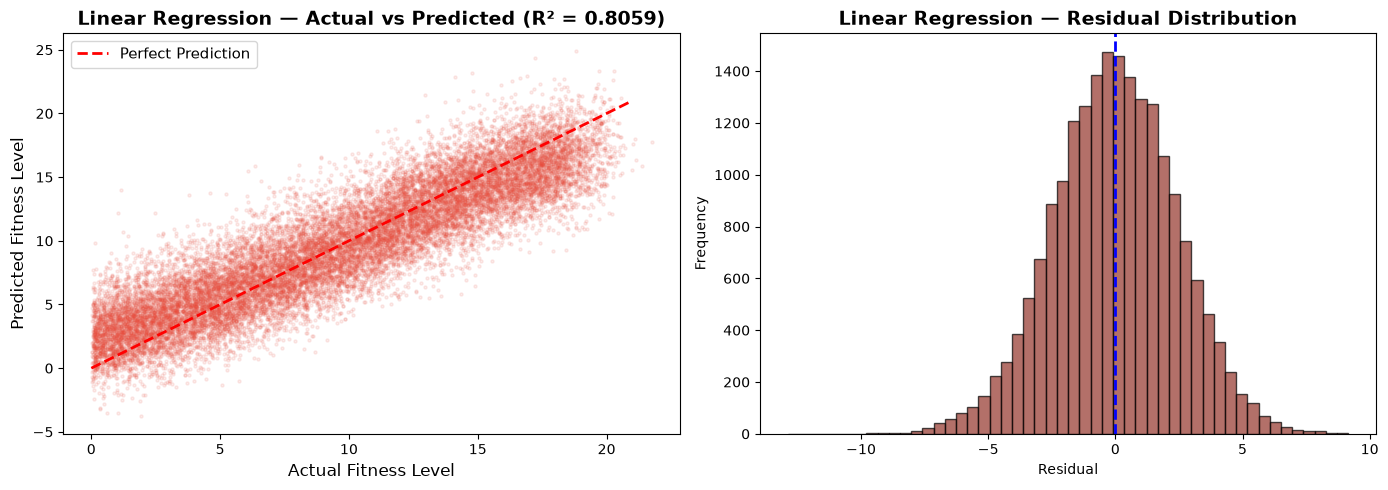

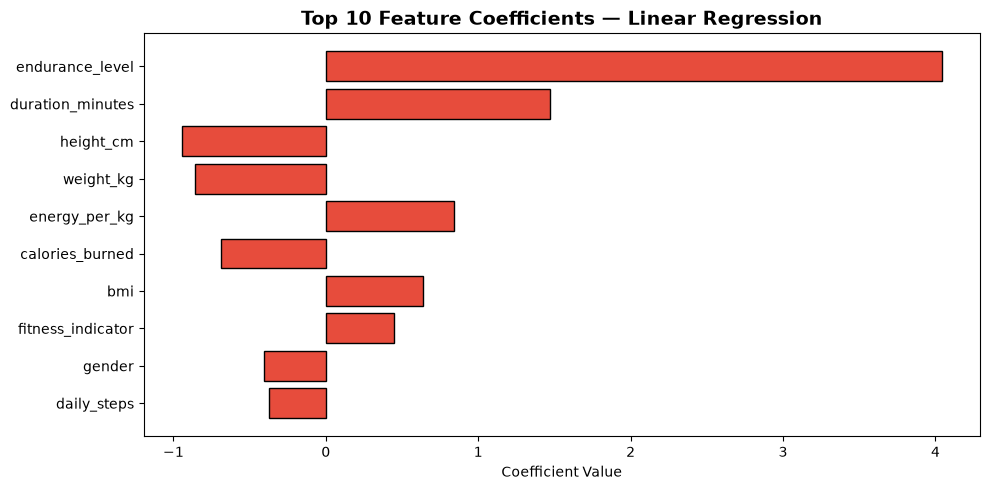

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test_reg, y_pred_lr, alpha=0.1, s=5, color='#e74c3c')
axes[0].plot([0, 21], [0, 21], 'r--', linewidth=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Fitness Level', fontsize=12)
axes[0].set_ylabel('Predicted Fitness Level', fontsize=12)
axes[0].set_title(f'Linear Regression — Actual vs Predicted (R² = {lr_r2:.4f})', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)

residuals_lr = y_test_reg - y_pred_lr
axes[1].hist(residuals_lr, bins=50, color="#93342a", edgecolor='black', alpha=0.7)
axes[1].axvline(0, color='blue', linestyle='--', linewidth=2)
axes[1].set_title('Linear Regression — Residual Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

feature_importance = pd.DataFrame({
    'Feature': X_reg.columns,
    'Coefficient': lr_model.coef_
}).sort_values('Coefficient', key=abs, ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.barh(feature_importance['Feature'], feature_importance['Coefficient'], color='#e74c3c', edgecolor='black')
plt.title('Top 10 Feature Coefficients — Linear Regression', fontsize=14, fontweight='bold')
plt.xlabel('Coefficient Value')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [133]:
from xgboost import XGBClassifier
xgb_clf = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)
xgb_clf.fit(X_train_clf_scaled, y_train_clf)
y_pred_log = xgb_clf.predict(X_test_clf_scaled)

# Evaluate
log_acc = accuracy_score(y_test_clf, y_pred_log)
log_f1 = f1_score(y_test_clf, y_pred_log, average='weighted')
log_precision = precision_score(y_test_clf, y_pred_log, average='weighted')
log_recall = recall_score(y_test_clf, y_pred_log, average='weighted')

classification_results['XGBoost Classifier'] = {
    'Accuracy': log_acc, 'F1-Score': log_f1,
    'Precision': log_precision, 'Recall': log_recall
}

print("=" * 50)
print("     XGBoost Classifier Results")
print("=" * 50)
print(f"  Accuracy  = {log_acc:.4f}")
print(f"  Precision = {log_precision:.4f}")
print(f"  Recall    = {log_recall:.4f}")
print(f"  F1-Score  = {log_f1:.4f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_log, target_names=['Low', 'Medium', 'High']))

print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_log, target_names=['Low', 'Medium', 'High']))

     XGBoost Classifier Results
  Accuracy  = 0.8532
  Precision = 0.8533
  Recall    = 0.8532
  F1-Score  = 0.8531

Classification Report:
              precision    recall  f1-score   support

         Low       0.91      0.89      0.90      7241
      Medium       0.80      0.79      0.80      7259
        High       0.85      0.88      0.86      5500

    accuracy                           0.85     20000
   macro avg       0.85      0.86      0.85     20000
weighted avg       0.85      0.85      0.85     20000


Classification Report:
              precision    recall  f1-score   support

         Low       0.91      0.89      0.90      7241
      Medium       0.80      0.79      0.80      7259
        High       0.85      0.88      0.86      5500

    accuracy                           0.85     20000
   macro avg       0.85      0.86      0.85     20000
weighted avg       0.85      0.85      0.85     20000



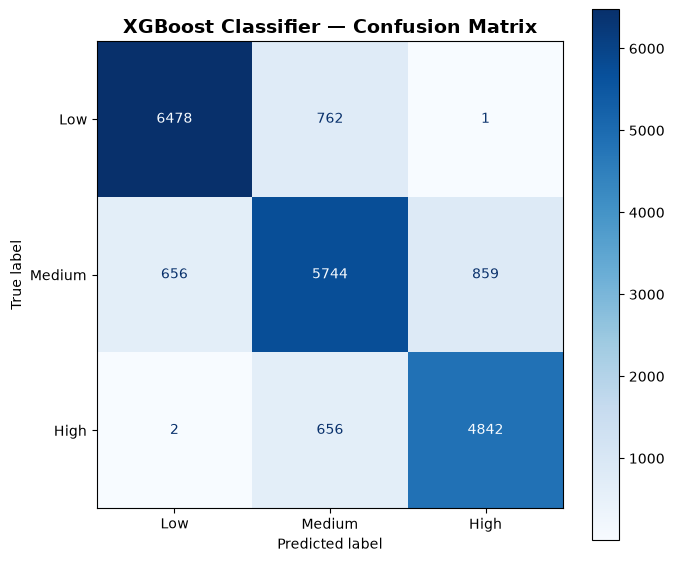

In [134]:
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test_clf, y_pred_log)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low', 'Medium', 'High'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title('XGBoost Classifier — Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [135]:
xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=20,
    eval_metric='rmse'
)

xgb_model.fit(
    X_train_reg_scaled, y_train_reg,
    eval_set=[(X_test_reg_scaled, y_test_reg)],
    verbose=50
)

y_pred_xgb = xgb_model.predict(X_test_reg_scaled)

xgb_mae = mean_absolute_error(y_test_reg, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_xgb))
xgb_r2 = r2_score(y_test_reg, y_pred_xgb)

regression_results['XGBoost'] = {'MAE': xgb_mae, 'RMSE': xgb_rmse, 'R²': xgb_r2}

print("\n" + "=" * 50)
print("     XGBoost Regression Results")
print("=" * 50)
print(f"  MAE  = {xgb_mae:.4f}")
print(f"  RMSE = {xgb_rmse:.4f}")
print(f"  R²   = {xgb_r2:.4f}")
print("=" * 50)


[0]	validation_0-rmse:5.09152
[50]	validation_0-rmse:2.14684
[100]	validation_0-rmse:2.00173
[150]	validation_0-rmse:1.89994
[200]	validation_0-rmse:1.81093
[250]	validation_0-rmse:1.73461
[300]	validation_0-rmse:1.66798
[350]	validation_0-rmse:1.60183
[400]	validation_0-rmse:1.54404
[450]	validation_0-rmse:1.48217
[499]	validation_0-rmse:1.42896

     XGBoost Regression Results
  MAE  = 1.0921
  RMSE = 1.4290
  R²   = 0.9328


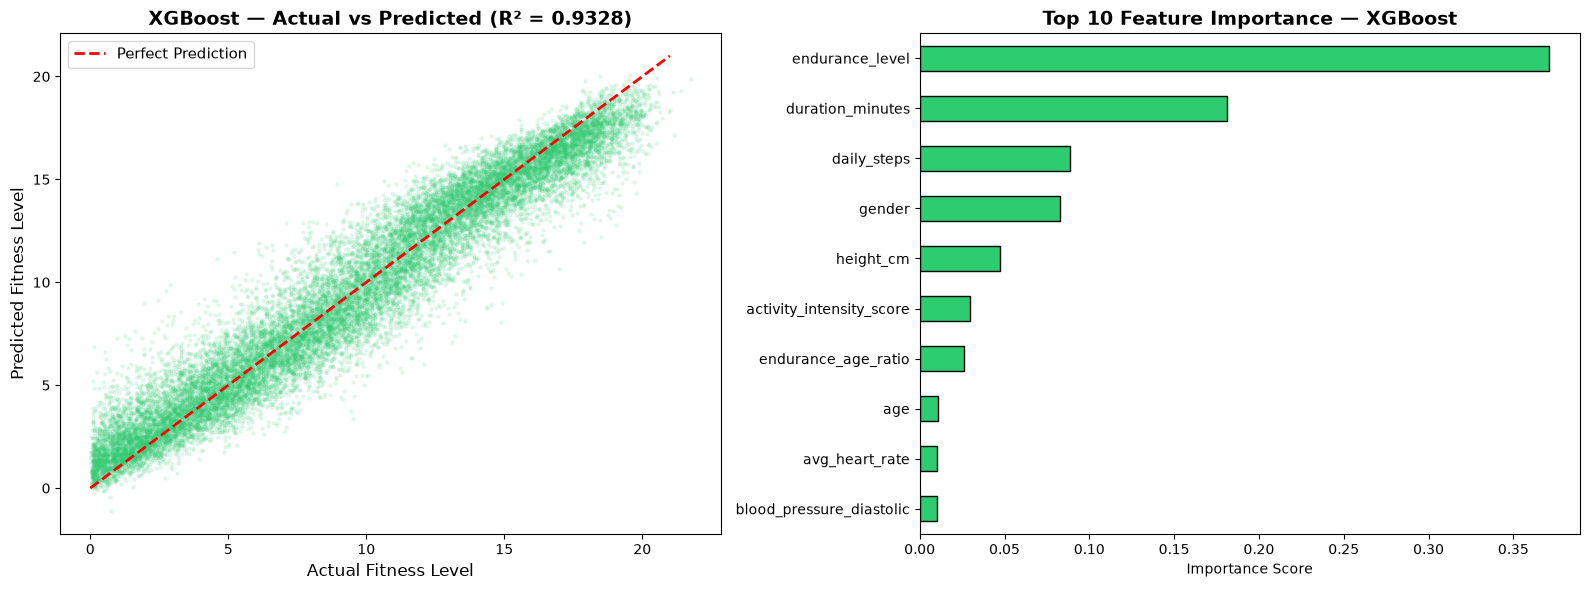

In [136]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot
axes[0].scatter(y_test_reg, y_pred_xgb, alpha=0.1, s=5, color='#2ecc71')
axes[0].plot([0, 21], [0, 21], 'r--', linewidth=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Fitness Level', fontsize=12)
axes[0].set_ylabel('Predicted Fitness Level', fontsize=12)
axes[0].set_title(f'XGBoost — Actual vs Predicted (R² = {xgb_r2:.4f})', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)

feature_imp = pd.Series(xgb_model.feature_importances_, index=X_reg.columns)
top_features = feature_imp.nlargest(10)
top_features.plot.barh(ax=axes[1], color='#2ecc71', edgecolor='black')
axes[1].set_title('Top 10 Feature Importance — XGBoost', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Importance Score')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


In [137]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# Train SVM 
svm_model = LinearSVC(
    C=1.0,
    max_iter=5000,
    dual='auto',
    random_state=42
)
svm_model.fit(X_train_clf_scaled, y_train_clf)
y_pred_svm = svm_model.predict(X_test_clf_scaled)

# Evaluate
svm_acc = accuracy_score(y_test_clf, y_pred_svm)
svm_f1 = f1_score(y_test_clf, y_pred_svm, average='weighted')
svm_precision = precision_score(y_test_clf, y_pred_svm, average='weighted')
svm_recall = recall_score(y_test_clf, y_pred_svm, average='weighted')

classification_results['SVM'] = {
    'Accuracy': svm_acc, 'F1-Score': svm_f1,
    'Precision': svm_precision, 'Recall': svm_recall
}

print("=" * 50)
print("     SVM Classification Results")
print("=" * 50)
print(f"  Accuracy  = {svm_acc:.4f}")
print(f"  Precision = {svm_precision:.4f}")
print(f"  Recall    = {svm_recall:.4f}")
print(f"  F1-Score  = {svm_f1:.4f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_svm, target_names=['Low', 'Medium', 'High']))


     SVM Classification Results
  Accuracy  = 0.7627
  Precision = 0.7619
  Recall    = 0.7627
  F1-Score  = 0.7502

Classification Report:
              precision    recall  f1-score   support

         Low       0.78      0.92      0.84      7241
      Medium       0.76      0.51      0.61      7259
        High       0.74      0.89      0.81      5500

    accuracy                           0.76     20000
   macro avg       0.76      0.77      0.76     20000
weighted avg       0.76      0.76      0.75     20000



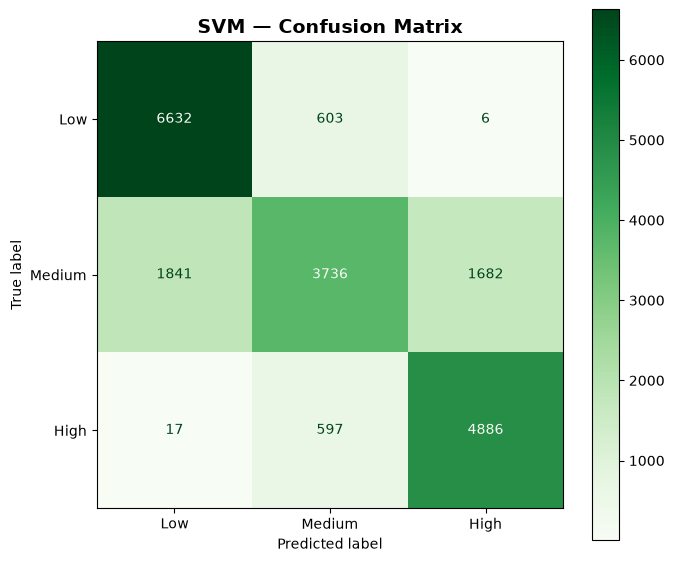

In [138]:

fig, ax = plt.subplots(figsize=(7, 6))
cm_svm = confusion_matrix(y_test_clf, y_pred_svm)
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=['Low', 'Medium', 'High'])
disp_svm.plot(cmap='Greens', ax=ax, values_format='d')
ax.set_title('SVM — Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [139]:
print("=" * 70)
print("              REGRESSION MODELS COMPARISON")
print("=" * 70)

reg_df = pd.DataFrame(regression_results).T
reg_df = reg_df.round(4)
reg_df.index.name = 'Model'
print(reg_df.to_string())
print()

best_reg = reg_df['R²'].idxmax()
print(f" Best Regression Model: {best_reg} (R² = {reg_df.loc[best_reg, 'R²']:.4f})")

print("\n" + "=" * 70)
print("              CLASSIFICATION MODELS COMPARISON")
print("=" * 70)

clf_df = pd.DataFrame(classification_results).T
clf_df = clf_df.round(4)
clf_df.index.name = 'Model'
print(clf_df.to_string())
print()

best_clf = clf_df['Accuracy'].idxmax()
print(f" Best Classification Model: {best_clf} (Accuracy = {clf_df.loc[best_clf, 'Accuracy']:.4f})")


              REGRESSION MODELS COMPARISON
                      MAE    RMSE      R²
Model                                    
KNN                2.5127  3.1061  0.6824
Linear Regression  1.9299  2.4286  0.8059
XGBoost            1.0921  1.4290  0.9328

 Best Regression Model: XGBoost (R² = 0.9328)

              CLASSIFICATION MODELS COMPARISON
                    Accuracy  F1-Score  Precision  Recall
Model                                                    
XGBoost Classifier    0.8532    0.8531     0.8533  0.8532
SVM                   0.7627    0.7502     0.7619  0.7627

 Best Classification Model: XGBoost Classifier (Accuracy = 0.8532)


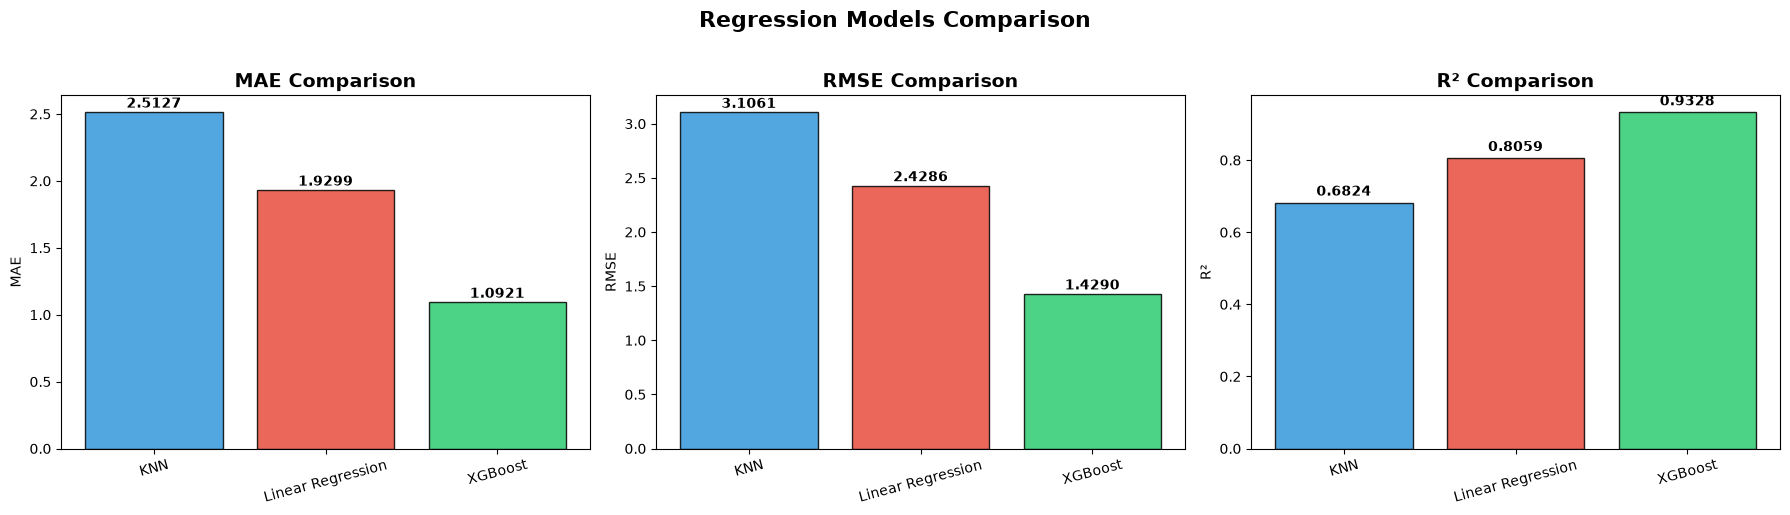

In [140]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = ['MAE', 'RMSE', 'R²']
colors_reg = ['#3498db', '#e74c3c', '#2ecc71']

for i, metric in enumerate(metrics):
    bars = axes[i].bar(reg_df.index, reg_df[metric], color=colors_reg, edgecolor='black', alpha=0.85)
    axes[i].set_title(f'{metric} Comparison', fontsize=14, fontweight='bold')
    axes[i].set_ylabel(metric)
    # Add value labels
    for bar, val in zip(bars, reg_df[metric]):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                     f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=15)

fig.suptitle('Regression Models Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


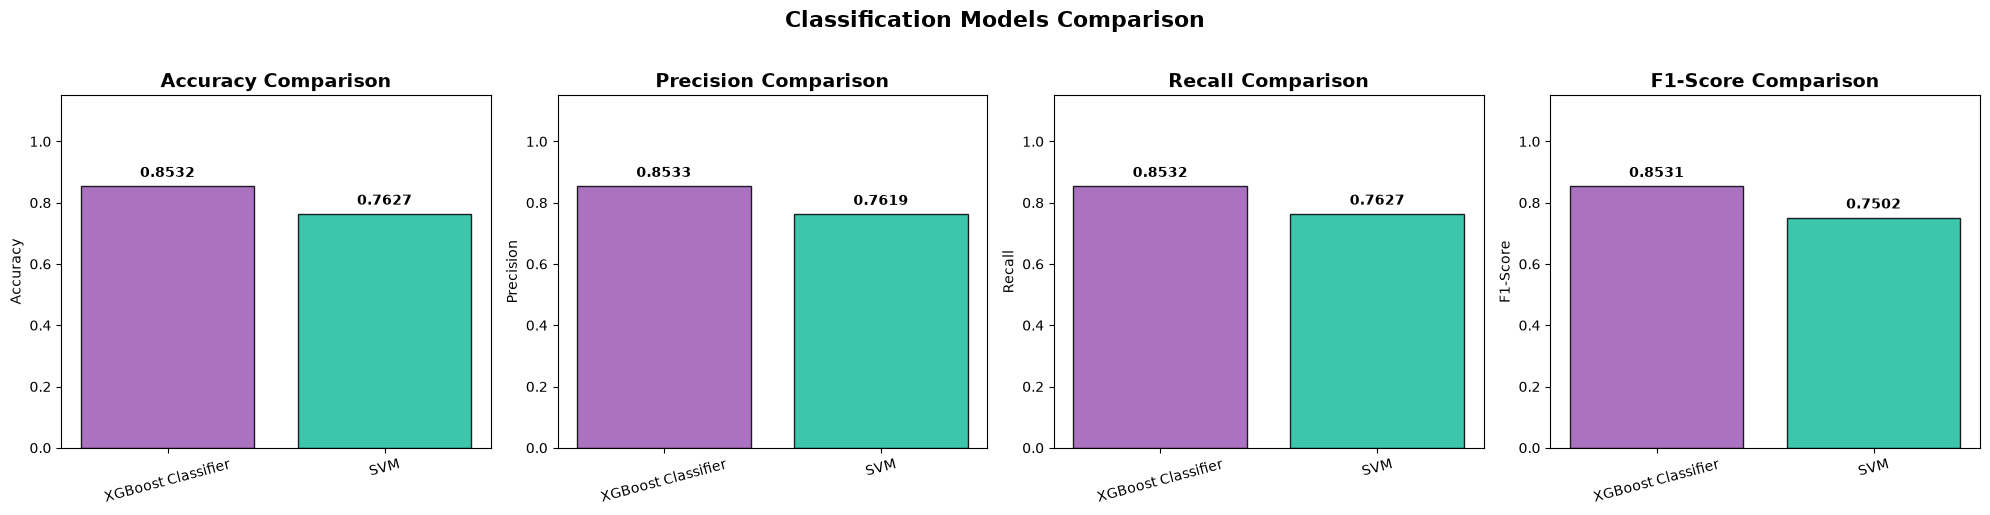

In [141]:

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
clf_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors_clf = ['#9b59b6', '#1abc9c']

for i, metric in enumerate(clf_metrics):
    bars = axes[i].bar(clf_df.index, clf_df[metric], color=colors_clf, edgecolor='black', alpha=0.85)
    axes[i].set_title(f'{metric} Comparison', fontsize=14, fontweight='bold')
    axes[i].set_ylabel(metric)
    axes[i].set_ylim(0, 1.15)
    for bar, val in zip(bars, clf_df[metric]):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                     f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=15)

fig.suptitle('Classification Models Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [142]:

os.makedirs('saved_models', exist_ok=True)


joblib.dump(knn_model, 'saved_models/knn_model.pkl')
joblib.dump(lr_model, 'saved_models/linear_regression_model.pkl')
joblib.dump(xgb_model, 'saved_models/xgboost_model.pkl')


joblib.dump(xgb_model, 'saved_models/xgboost_model.pkl')
joblib.dump(svm_model, 'saved_models/svm_model.pkl')

joblib.dump(scaler_reg, 'saved_models/scaler_regression.pkl')
joblib.dump(scaler_clf, 'saved_models/scaler_classification.pkl')

joblib.dump(le_gender, 'saved_models/label_encoder_gender.pkl')

feature_names = list(X_reg.columns)
joblib.dump(feature_names, 'saved_models/feature_names.pkl')

print(" All models saved successfully to 'saved_models/' directory!")
print()
for f in sorted(os.listdir('saved_models')):
    size = os.path.getsize(f'saved_models/{f}') / 1024
    print(f"  {f:45s}  ({size:,.1f} KB)")


 All models saved successfully to 'saved_models/' directory!

  feature_names.pkl                              (0.8 KB)
  knn_model.pkl                                  (27,500.7 KB)
  label_encoder_gender.pkl                       (0.5 KB)
  linear_regression_model.pkl                    (1.3 KB)
  scaler_classification.pkl                      (2.6 KB)
  scaler_regression.pkl                          (2.6 KB)
  svm_model.pkl                                  (1.8 KB)
  xgboost_classifier.pkl                         (18,058.4 KB)
  xgboost_model.pkl                              (2,374.7 KB)
